In [31]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.optimize import linear_sum_assignment

from gm.models.energy_matching_model import sample_emm, ot_couple, grad_V, langevin_negative_samples, ode_integrate

In [32]:
SEED = 42
DEVICE = 'mps'

batch_size = 128
lr = 1e-4
eps_max = 0.05

emm_phase1_steps = 5_000
emm_phase2_steps = 500
cd_weight = 1.0

In [33]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True, drop_last=True)

In [34]:
def sample_noise(batch_size):
    return torch.randn(batch_size, 1, 28, 28)

train_iter = iter(train_loader)
def sample_data(batch_size):
    global train_iter
    try:
        return next(train_iter)[0]
    except StopIteration:
        train_iter = iter(train_loader)
        return next(train_iter)[0]

In [35]:
def fit_pca_basis(data_sample, n_components=32):
    # data_sample: (N, 1, 28, 28) or (N, 784) tensor of real MNIST images
    x_flat = data_sample.flatten(1)
    mean = x_flat.mean(dim=0, keepdim=True)
    centered = x_flat - mean
    _, _, V = torch.pca_lowrank(centered, q=n_components)
    return mean.to(DEVICE), V.to(DEVICE)  # mean: (1, 784), V: (784, n_components)


data = sample_data(1024)
mean, V = fit_pca_basis(data)

In [36]:
def plot_losses(losses, color = 'tab:blue'):
    fig, ax = plt.subplots()

    ax.plot(losses, label="Loss", color=color, alpha=0.5)
    ws = 100
    smoothed = np.convolve(losses, np.ones(ws)/ws, mode="valid")
    ax.plot(np.arange(ws-1, len(losses)), smoothed, label="Smoothed Loss", color=color)

    plt.legend()
    plt.grid()
    plt.show()

def plot_samples(x, n_cols=8, figsize_scale=1.2):
    # x = x.detach().cpu().view(-1, 28, 28)  # (N, 784) -> (N, 28, 28)
    x = x.detach().cpu().squeeze(1)  
    n = x.shape[0]
    n_cols = min(n_cols, n)
    n_rows = (n + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * figsize_scale, n_rows * figsize_scale))
    axes = axes.flatten() if n > 1 else [axes]

    for i, ax in enumerate(axes):
        if i < n:
            ax.imshow(x[i], cmap="gray")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [53]:
class EnergyMatchingCNN(nn.Module):
    def __init__(self, in_ch=1, base_ch=32, hidden_dim=256, output_scale=5000.0):
        super().__init__()

        # TODO: Why is this a scaler? Would a logorithmic function help here so that the small values are scaled but the large ones stay?
        self.output_scale = output_scale 

        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, base_ch, 3, padding=1),
            nn.SiLU(),
            nn.Conv2d(base_ch, base_ch, 3, padding=1),
            nn.SiLU(),
            nn.Conv2d(base_ch, base_ch * 2, 4, stride=2, padding=1),
            nn.SiLU(),
            nn.Conv2d(base_ch * 2, base_ch * 2, 3, padding=1),
            nn.SiLU(),
            nn.Conv2d(base_ch * 2, base_ch * 4, 4, stride=2, padding=1),
            nn.SiLU()
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.head = nn.Sequential(
            nn.Linear(base_ch * 4, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        h = self.conv(x)
        h = self.pool(h).flatten(1)
        return self.head(h) * self.output_scale

In [51]:

def project(x, mean, V):
    return (x.flatten(1) - mean) @ V  # (B, n_components)

def ot_couple(x0, x1):
    cost = torch.cdist(x0.flatten(1), x1.flatten(1)) ** 2
    row_ind, col_ind = linear_sum_assignment(cost.cpu().detach().numpy())

    return x0[row_ind], x1[col_ind]

def ot_pca_couple(x0, x1, pca_mean, pca_V):
    f0 = project(x0, pca_mean, pca_V)
    f1 = project(x1, pca_mean, pca_V)

    cost = torch.cdist(f0, f1) ** 2
    row_ind, col_ind = linear_sum_assignment(cost.cpu().detach().numpy())

    return x0[row_ind], x1[col_ind]

def phase1_loss(V, x_0, x_1, t):
    x_0, x_1 = ot_couple(x_0, x_1)

    x_t = (1 - t) * x_0 + t * x_1
    target = x_0 - x_1
    pred = grad_V(V, x_t)

    return ((pred - target) ** 2).sum(dim=1).mean()

def phase1_pca_loss(V, x_0, x_1, t, pca_mean, pca_V):
    x_0, x_1 = ot_pca_couple(x_0, x_1, pca_mean, pca_V)

    x_t = (1 - t) * x_0 + t * x_1
    target = x_0 - x_1
    pred = grad_V(V, x_t)

    return ((pred - target) ** 2).sum(dim=1).mean()


def phase2_loss(V, x_0, x_1, t, eps_max = 0.05, cd_weight = 1.0, alpha=0.1):
    ot_loss = phase1_loss(V, x_0, x_1, t)

    half = x_1.shape[0] // 2
    x_0 = x_0[:half]
    x0_pushed = ode_integrate(V, x_0, n_steps=50)
    x_init = torch.cat([x_1[:half] + 0.1 * torch.randn_like(x_1[:half]), x0_pushed], dim=0)

    x_neg = langevin_negative_samples(V, x_init, eps_max=eps_max)

    v_data = V(x_1)
    v_neg = V(x_neg)

    cd_loss = v_data.mean() / eps_max - v_neg.mean() / eps_max
    reg = alpha * (v_data ** 2 + v_neg ** 2).mean()

    return ot_loss + cd_weight * cd_loss + reg

def phase2_pca_loss(V, x_0, x_1, t, pca_mean, pca_V, eps_max = 0.05, cd_weight = 1.0, alpha=0.1):
    ot_loss = phase1_pca_loss(V, x_0, x_1, t, pca_mean, pca_V)

    half = x_1.shape[0] // 2
    x_0 = x_0[:half]
    x0_pushed = ode_integrate(V, x_0, n_steps=10)
    x_init = torch.cat([x_1[:half] + 0.1 * torch.randn_like(x_1[:half]), x0_pushed], dim=0)

    x_neg = langevin_negative_samples(V, x_init, eps_max=eps_max)

    v_data = V(x_1)
    v_neg = V(x_neg)

    cd_loss = v_data.mean() / eps_max - v_neg.mean() / eps_max
    reg = alpha * (v_data ** 2 + v_neg ** 2).mean()

    return ot_loss + cd_weight * cd_loss + reg


In [54]:
emm = EnergyMatchingCNN().to(DEVICE)
optimizer = torch.optim.Adam(emm.parameters(), lr)

In [55]:
def zero_loss(x_0, x_1, mean, V):
    x_0, x_1 = ot_pca_couple(x_0, x_1, mean, V)

    # x_t = (1 - t) * x_0 + t * x_1
    target = x_0 - x_1
    pred = torch.zeros_like(x_1)

    return ((pred - target) ** 2).sum(dim=1).mean()

x_0 = sample_noise(batch_size).to(DEVICE)
x_1 = sample_data(batch_size).to(DEVICE)
zero_loss(x_0, x_1, mean, V)

tensor(1.8642, device='mps:0')

100%|██████████| 5000/5000 [05:39<00:00, 14.72it/s, Loss=0.28]


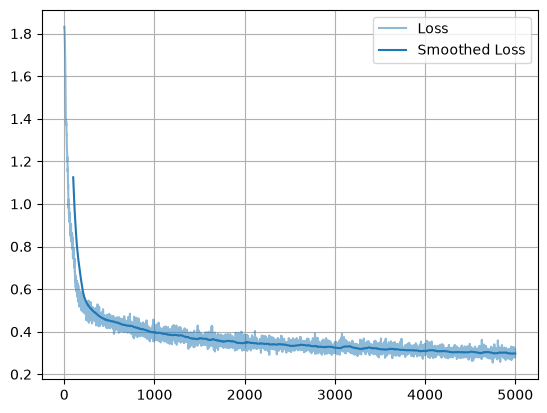

In [56]:
emm.train()
phase1_losses = []
with tqdm(range(emm_phase1_steps)) as pb:
    for i in pb:
        x_0 = sample_noise(batch_size).to(DEVICE)
        x_1 = sample_data(batch_size).to(DEVICE)
        t = torch.rand(x_0.shape[0], 1, 1, 1, device=DEVICE)

        optimizer.zero_grad()
        loss = phase1_loss(emm, x_0, x_1, t)
        loss.backward()
        optimizer.step() 

        pb.set_postfix({'Loss': f'{loss.item():.2f}'})
        phase1_losses.append(loss.item())

plot_losses(phase1_losses, color='tab:blue')


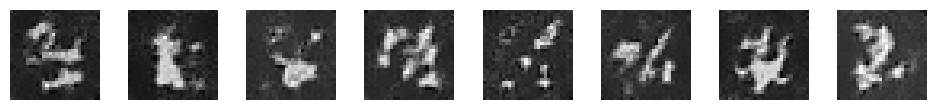

In [57]:
emm.eval()
x_0 = sample_noise(8).to(DEVICE)

# Phase 1 only
samples = ode_integrate(emm, x_0, n_steps=50)

plot_samples(samples)

In [43]:
# emm.train()
# phase2_losses = []
# with tqdm(range(emm_phase2_steps)) as pb:
#     for i in pb:
#         x_0 = sample_noise(batch_size).to(DEVICE)
#         x_1 = sample_data(batch_size).to(DEVICE)
#         t = torch.rand(x_0.shape[0], 1, 1, 1, device=DEVICE)

#         optimizer.zero_grad()
#         loss = phase2_loss(emm, x_0, x_1, t, eps_max, cd_weight, alpha=0.3)
#         loss.backward()
#         optimizer.step() 

#         pb.set_postfix({'Loss': f'{loss.item():.2f}'})
#         phase2_losses.append(loss.item())


# plot_losses(phase2_losses, color='tab:orange')

In [44]:
# emm.eval()
# x_0 = sample_noise(8).to(DEVICE)

# samples = sample_emm(emm, x_0, ode_steps=20, langevin_steps=10, eps_max=eps_max).cpu()
# plot_samples(samples)